# F1 Telemetry Explorer: Analysis

This is the analysis behind the Streamlit app (`app.py`). I pulled each driver's fastest qualifying lap from the 2025 Italian GP with FastF1.

I wanted to see where one driver gains time on another, and whether that's from going faster on the straights or carrying more speed through the corners.

1. Load data
2. Variable audit
3. Data-quality checks
4. Q1: Where did Verstappen gain pole over Norris?
5. Q2: Across the grid, does top speed or corner speed track lap time?
6. Why I lined the laps up on lap fraction instead of time

The helper functions are in `f1_analysis.py`. The first run downloads the session into `f1_cache/` and needs internet.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import f1_analysis as f1a

## 1. Load data

In [2]:
session = f1a.load_session(2025, "Italian Grand Prix", "Q")
laps = f1a.get_laps(session)
tel = f1a.build_telemetry(laps)

print("Telemetry:", tel.shape)
print("Laps:", laps.shape)
tel.head()

Telemetry: (12008, 25)
Laps: (315, 31)


,Date,SessionTime,DriverAhead,DistanceToDriverAhead,Time,RPM,Speed,nGear,Throttle,Brake,...,X,Y,Z,Driver,Team,LapTime_s,Compound,TireLife,FreshTire,LapFrac
0,2025-09-06 15:00:53.955,0 days 01:13:33.378000,,802.070000,0 days 00:00:00,11381.404580,321.645455,8,100.0,False,...,-1373.650597,-676.336105,1871.232164,VER,Red Bull Racing,78.792,SOFT,2.0,True,0.000003
1,2025-09-06 15:00:54.242,0 days 01:13:33.665000,,802.070000,0 days 00:00:00.287000,11459.024983,322.950000,8,100.0,False,...,-1346.000000,-352.000000,1873.000000,VER,Red Bull Racing,78.792,SOFT,2.0,True,0.004487
2,2025-09-06 15:00:54.253,0 days 01:13:33.676000,,802.070000,0 days 00:00:00.298000,11462.000000,323.000000,8,100.0,False,...,-1345.304479,-344.042629,1873.058849,VER,Red Bull Racing,78.792,SOFT,2.0,True,0.004660
3,2025-09-06 15:00:54.414,0 days 01:13:33.837000,4,802.070000,0 days 00:00:00.459000,11415.000000,326.000000,8,100.0,False,...,-1337.809285,-260.635587,1873.822443,VER,Red Bull Racing,78.792,SOFT,2.0,True,0.007194
4,2025-09-06 15:00:54.502,0 days 01:13:33.925000,4,797.767775,0 days 00:00:00.547000,11446.376061,326.490251,8,100.0,False,...,-1333.000000,-207.000000,1874.000000,VER,Red Bull Racing,78.792,SOFT,2.0,True,0.008583


## 2. Variable audit

These are the columns I actually used.

In [3]:
audit = pd.DataFrame({
    "Variable": ["Driver", "Distance", "Speed", "Throttle", "Brake", "nGear", "X", "LapTime_s",
                 "Compound", "TireLife", "FreshTire", "DRS"],
    "Role": ["driver / app dropdown", "x-axis", "main signal", "full throttle or not", "braking zones",
             "gear", "track map (with Y)", "outcome", "tire type", "tire age", "new or used tires", "rear wing flap open or closed"],
    "Type": ["categorical", "quantitative (m)", "quantitative (km/h)", "quantitative (%)", "categorical (on/off)",
             "ordinal (2-8)", "quantitative", "quantitative (s)", "categorical", "quantitative (laps)", "categorical", "categorical (coded)"],
    "Transform?": ["no", "yes, divide by lap length", "no", "no", "no", "no", "no", "yes, timedelta to seconds",
                   "no", "no", "no", "yes, codes 10/12/14 mean open"],
})
audit["dtype"] = [str(tel[col].dtype) for col in audit["Variable"]]
audit

,Variable,Role,Type,Transform?,dtype
0,Driver,driver / app dropdown,categorical,no,object
1,Distance,x-axis,quantitative (m),"yes, divide by lap length",float64
2,Speed,main signal,quantitative (km/h),no,float64
3,Throttle,full throttle or not,quantitative (%),no,float64
4,Brake,braking zones,categorical (on/off),no,bool
5,nGear,gear,ordinal (2-8),no,int64
6,X,track map (with Y),quantitative,no,float64
7,LapTime_s,outcome,quantitative (s),"yes, timedelta to seconds",float64
8,Compound,tire type,categorical,no,object
9,TireLife,tire age,quantitative (laps),no,float64


## 3. Data-quality checks

In [4]:
missing = tel.isna().sum()
print("Missing values:")
print(missing[missing > 0])

print("\nDuplicate telemetry rows:", tel.duplicated().sum())
print("Duplicate laps:", laps.duplicated(subset=["Driver", "LapNumber"]).sum())
print("Laps without a lap time:", laps["LapTime"].isna().sum(), "out of", len(laps))

print("\nThrottle outside 0-100:", ((tel["Throttle"] < 0) | (tel["Throttle"] > 100)).sum())
print("Speed <= 0 or > 370 km/h:", ((tel["Speed"] <= 0) | (tel["Speed"] > 370)).sum())

print("\nRow source:")
print(tel["Source"].value_counts())

Missing values:
DistanceToDriverAhead    1198
dtype: int64

Duplicate telemetry rows: 0
Duplicate laps: 0
Laps without a lap time: 106 out of 315

Throttle outside 0-100: 0
Speed <= 0 or > 370 km/h: 0

Row source:
Source
pos              6012
car              5956
interpolation      40
Name: count, dtype: int64


In [5]:
car = laps.pick_drivers("VER").pick_fastest().get_car_data()
sample_gaps = car["Time"].diff().dt.total_seconds()
print("Median time between car samples (s):", round(sample_gaps.median(), 3))
print("Longest gap between car samples (s):", round(sample_gaps.max(), 3))

lap_length = tel.groupby("Driver")["Distance"].max()
print("Lap length range (m):", round(lap_length.min()), "to", round(lap_length.max()))

Median time between car samples (s): 0.241
Longest gap between car samples (s): 0.961
Lap length range (m): 5742 to 5772


In [6]:
tires = tel.groupby("Driver")[["Compound", "TireLife", "FreshTire"]].first()
print("Missing tire values in laps table:", laps[["Compound", "TireLife", "FreshTire"]].isna().sum().sum())
print("Compounds on fastest laps:", tires["Compound"].value_counts().to_dict())
print("Fresh tire sets on fastest laps:", tires["FreshTire"].sum(), "of", len(tires))
print("Drivers on a used set:")
print(tires[tires["FreshTire"] == False])

# DRS: how far each driver drove with the flap open
drs_m = []
for driver in tel["Driver"].unique():
    drs_m.append(f1a.drs_open_distance(tel[tel["Driver"] == driver]))
print("\nDRS open distance on fastest laps (m):", round(min(drs_m)), "to", round(max(drs_m)))

tel[["Speed", "Throttle", "RPM", "nGear"]].describe().round(1)

Missing tire values in laps table: 0
Compounds on fastest laps: {'SOFT': 20}
Fresh tire sets on fastest laps: 19 of 20
Drivers on a used set:
       Compound  TireLife  FreshTire
Driver                              
SAI        SOFT       5.0      False

DRS open distance on fastest laps (m): 1521 to 1596


,Speed,Throttle,RPM,nGear
count,12008.0,12008.0,12008.0,12008.0
mean,261.0,81.0,10991.7,6.5
std,71.6,36.1,1103.7,1.8
min,68.0,0.0,5404.0,2.0
25%,220.4,94.8,10757.0,6.0
50%,275.8,100.0,11230.1,7.0
75%,321.0,100.0,11632.0,8.0
max,356.0,100.0,12895.0,8.0


What I ended up doing with the data:

- I only kept each driver's fastest timed lap. The untimed ones are out/in laps, not holes in the data. Filling those in would just invent laps that didn't count.
- I used the official sector times for gaps. If I integrate speed over distance, the lap length isn't even the same for every driver (about 30 m of spread), and that is already bigger than the pole margin.
- Tires and DRS barely move in this session. Every fastest lap was on Softs, 19 of 20 on a fresh set, and DRS was open for about 1.5 km for everyone. I can't use this qualifying data to talk about how tires or DRS change performance.
- The charts use lap fraction (distance / that driver's lap length) on the x-axis. That puts the same corner in the same place. Section 6 is me checking that against lining them up by time.

## 4. Q1: Where did Verstappen gain pole over Norris?

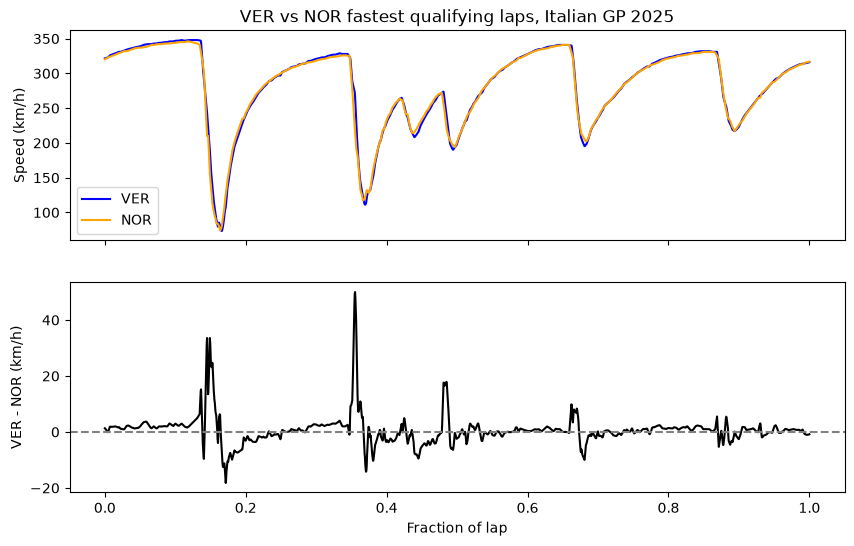

VER faster on 62 % of the lap


In [7]:
ver_lap = laps.pick_drivers("VER").pick_fastest()
nor_lap = laps.pick_drivers("NOR").pick_fastest()
ver = tel[tel["Driver"] == "VER"]
nor = tel[tel["Driver"] == "NOR"]

x, ver_speed = f1a.speed_on_grid(ver)
_, nor_speed = f1a.speed_on_grid(nor)
speed_diff = ver_speed - nor_speed

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(x, ver_speed, color="blue", label="VER")
ax1.plot(x, nor_speed, color="orange", label="NOR")
ax1.set_ylabel("Speed (km/h)")
ax1.set_title("VER vs NOR fastest qualifying laps, Italian GP 2025")
ax1.legend()
ax2.plot(x, speed_diff, color="black")
ax2.axhline(0, color="gray", linestyle="--")
ax2.set_ylabel("VER - NOR (km/h)")
ax2.set_xlabel("Fraction of lap")
plt.show()

print("VER faster on", round((speed_diff > 0).mean() * 100), "% of the lap")

In [8]:
summary = pd.DataFrame({"VER": f1a.lap_summary(ver_lap), "NOR": f1a.lap_summary(nor_lap)})
summary.loc["DRS open (m)"] = [f1a.drs_open_distance(ver), f1a.drs_open_distance(nor)]
summary["VER - NOR"] = summary["VER"] - summary["NOR"]
summary.round(3)

,VER,NOR,VER - NOR
Lap time,78.792,78.869,-0.077
Sector 1,26.262,26.378,-0.116
Sector 2,26.483,26.438,0.045
Sector 3,26.047,26.053,-0.006
Speed trap,348.000,345.000,3.000
Tire age (laps),2.000,2.000,0.000
DRS open (m),1522.371,1547.256,-24.885


In [9]:
corners = f1a.key_corners(session, lap_length.median())

corner_rows = []
for _, row in corners.iterrows():
    v = f1a.min_speed_near(ver, row["Frac"])
    n = f1a.min_speed_near(nor, row["Frac"])
    corner_rows.append([row["Name"], v, n, v - n])
pd.DataFrame(corner_rows, columns=["Corner", "VER min speed", "NOR min speed", "VER - NOR"])

,Corner,VER min speed,NOR min speed,VER - NOR
0,T1 chicane,73.0,74.0,-1.0
1,Roggia,111.0,117.0,-6.0
2,Lesmo 1,208.0,214.0,-6.0
3,Lesmo 2,190.0,194.0,-4.0
4,Ascari,195.0,202.0,-7.0
5,Parabolica,217.0,217.0,0.0


Verstappen took pole by 0.077 s, and that came from Sector 1 (he was 0.116 s faster there; Norris got a bit back in Sector 2). He was quicker on the straights (speed trap 348 vs 345 km/h). Norris actually had the higher minimum speeds at Roggia, the Lesmos, and Ascari.

This is only one lap each. Setup, fuel, or a tow could still be part of the gap. Tires and DRS aren't though. Both were on fresh Softs with 2 laps on them, and DRS was open for about 1.5 km (VER 1,522 m, NOR 1,547 m). The corner mins are also a little rough. The car data only comes in around 4 times a second.

## 5. Q2: Across the grid, does top speed or corner speed track lap time?

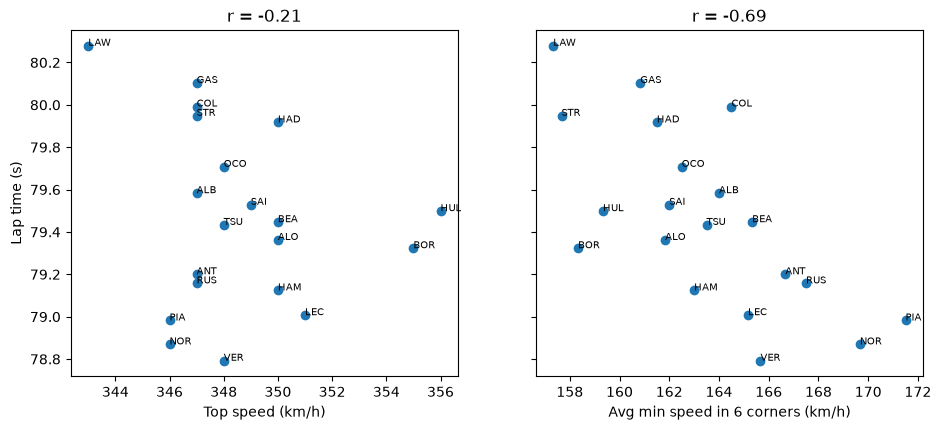

,LapTime_s,TopSpeed,CornerSpeed
count,20.00,20.0,20.00
mean,79.46,348.6,163.39
std,0.42,3.0,3.79
min,78.79,343.0,157.33
25%,79.15,347.0,161.33
50%,79.44,348.0,163.25
75%,79.76,350.0,165.42
max,80.28,356.0,171.50


In [10]:
drivers = f1a.driver_features(tel, corners)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
axes[0].scatter(drivers["TopSpeed"], drivers["LapTime_s"])
axes[1].scatter(drivers["CornerSpeed"], drivers["LapTime_s"])
for _, row in drivers.iterrows():
    axes[0].text(row["TopSpeed"], row["LapTime_s"], row["Driver"], fontsize=7)
    axes[1].text(row["CornerSpeed"], row["LapTime_s"], row["Driver"], fontsize=7)
axes[0].set_xlabel("Top speed (km/h)")
axes[1].set_xlabel("Avg min speed in 6 corners (km/h)")
axes[0].set_ylabel("Lap time (s)")
axes[0].set_title("r = " + str(round(drivers["TopSpeed"].corr(drivers["LapTime_s"]), 2)))
axes[1].set_title("r = " + str(round(drivers["CornerSpeed"].corr(drivers["LapTime_s"]), 2)))
plt.show()

drivers.describe().round(2)

In [11]:
speed_vars = drivers[["LapTime_s", "TopSpeed", "CornerSpeed"]]
print("Pearson:")
display(speed_vars.corr().round(2))

print("Spearman:")
speed_vars.corr(method="spearman").round(2)

Pearson:


,LapTime_s,TopSpeed,CornerSpeed
LapTime_s,1.00,-0.21,-0.69
TopSpeed,-0.21,1.00,-0.31
CornerSpeed,-0.69,-0.31,1.00


Spearman:


,LapTime_s,TopSpeed,CornerSpeed
LapTime_s,1.00,-0.14,-0.69
TopSpeed,-0.14,1.00,-0.30
CornerSpeed,-0.69,-0.30,1.00


Corner speed tracks lap time a lot more than top speed. Pearson and Spearman both show that. On this grid the quicker cars are mostly carrying more speed through the corners, not posting the highest top speed.

There are only 20 drivers, and teammates share a car. These points aren't independent. I'm not treating this as a causal result.

## 6. Why I lined the laps up on lap fraction

I tried lining VER (pole) and LAW (slowest) up by elapsed time and by fraction of the lap.

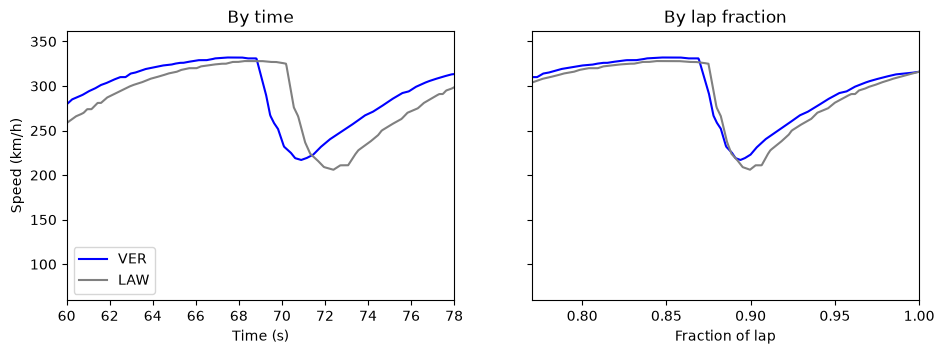

,r,mean abs speed diff (km/h)
by time,0.957,15.256
by lap fraction,0.994,5.939


In [12]:
ver_car = laps.pick_drivers("VER").pick_fastest().get_car_data().add_distance()
law_car = laps.pick_drivers("LAW").pick_fastest().get_car_data().add_distance()

ver_time = ver_car["Time"].dt.total_seconds()
law_time = law_car["Time"].dt.total_seconds()
time_grid = np.linspace(0, ver_time.max(), 3000)
ver_by_time = np.interp(time_grid, ver_time, ver_car["Speed"])
law_by_time = np.interp(time_grid, law_time, law_car["Speed"])

frac_grid = np.linspace(0, 1, 3000)
ver_by_frac = np.interp(frac_grid, ver_car["Distance"] / ver_car["Distance"].max(), ver_car["Speed"])
law_by_frac = np.interp(frac_grid, law_car["Distance"] / law_car["Distance"].max(), law_car["Speed"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
axes[0].plot(time_grid, ver_by_time, color="blue", label="VER")
axes[0].plot(time_grid, law_by_time, color="gray", label="LAW")
axes[0].set_xlim(60, 78)
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Speed (km/h)")
axes[0].set_title("By time")
axes[0].legend()
axes[1].plot(frac_grid, ver_by_frac, color="blue")
axes[1].plot(frac_grid, law_by_frac, color="gray")
axes[1].set_xlim(0.77, 1)
axes[1].set_xlabel("Fraction of lap")
axes[1].set_title("By lap fraction")
plt.show()

pd.DataFrame({
    "r": [np.corrcoef(ver_by_time, law_by_time)[0, 1], np.corrcoef(ver_by_frac, law_by_frac)[0, 1]],
    "mean abs speed diff (km/h)": [np.mean(np.abs(ver_by_time - law_by_time)), np.mean(np.abs(ver_by_frac - law_by_frac))],
}, index=["by time", "by lap fraction"]).round(3)

If I line them up by time, Lawson falls further behind as the lap goes on and the braking zones stop matching Verstappen's. Lap fraction keeps the corners in the same place. That's what I used in the charts and in the app.